In [1]:
pip install msprime

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 963.6/963.6 kB 8.0 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 773.5/773.5 kB 6.4 MB/s  0:00:00
  Created wheel for msprime: filename=msprime-1.4.0-cp310-cp310-macosx_11_0_x86_64.whl size=420763 sha256=de46d8759be32f43666130812dd7b4e22dccc345d62fb9675bd3b96873e69a04
  Stored in directory: /Users/macbook/Library/Caches/pip/wheels/df/34/07/a493c50e8db3ee947706427bc1ccf6ca1674bd87b00162dc84
Successfully built msprime
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [msprime]m4/5 [msprime]
Note: you may need to restart the kernel to use updated packages.


# msprime Intro

msprime is a Python library that simulates population genetic ancestries based on coalescent or related ancestry models.
The ancestry is represented as a tree sequence.

Typical workflow: define model > simulate ancestry > add mutations > analyse

In [ ]:
import msprime
from IPython.display import SVG, display

In [3]:
# Simulate ancestral history for 3 diploid individuals under coalescent
# with recombination on a 5kb region with human-like parameters

ts = msprime.sim_ancestry(samples=3, recombination_rate=1e-8, sequence_length=5_000, population_size=10_000, random_seed=123456)

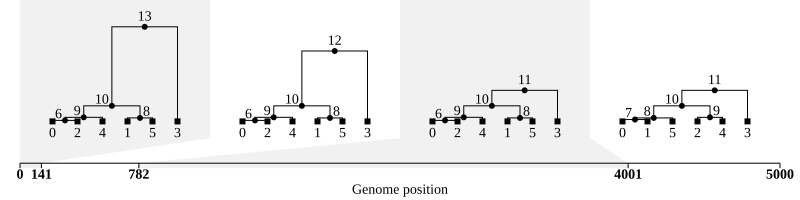

In [4]:
# Visualise the simulated ancestral history
SVG(ts.draw_svg())

In [5]:
# Include mutations to the generated tree
mutated_ts = msprime.sim_mutations(ts, rate=1e-8, random_seed=54321)

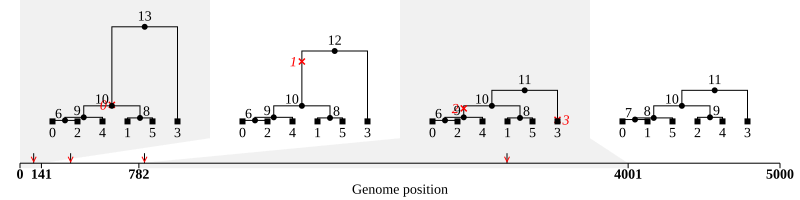

In [6]:
# Visualise mutation points on the trees
SVG(mutated_ts.draw_svg())

In [7]:
# Summarise of sites of mutations
mutated_ts.tables.sites

id,position,ancestral_state,metadata
0,90,T,
1,333,G,
2,819,T,
3,"3,204",A,


In [8]:
# Summarise of mutations
mutated_ts.tables.mutations

id,site,node,time,derived_state,parent,metadata
0,0,10,"12,191.40649541",G,-1,
1,1,10,"44,173.26473294",C,-1,
2,2,9,"9,597.21952351",G,-1,
3,3,3,"1,158.42914901",C,-1,


In [10]:
# To get information of each site od vatiation
for variant in mutated_ts.variants():
    print(variant)

╔═══════════════════════════════╗
║Variant                        ║
╠═══════════════════════╤═══════╣
║Site id                │      0║
╟───────────────────────┼───────╢
║Site position          │     90║
╟───────────────────────┼───────╢
║Number of samples      │      6║
╟───────────────────────┼───────╢
║Number of alleles      │      2║
╟───────────────────────┼───────╢
║Samples with allele 'T'│1 (17%)║
╟───────────────────────┼───────╢
║Samples with allele 'G'│5 (83%)║
╟───────────────────────┼───────╢
║Has missing data       │  False║
╟───────────────────────┼───────╢
║Isolated as missing    │   True║
╚═══════════════════════╧═══════╝

╔═══════════════════════════════╗
║Variant                        ║
╠═══════════════════════╤═══════╣
║Site id                │      1║
╟───────────────────────┼───────╢
║Site position          │    333║
╟───────────────────────┼───────╢
║Number of samples      │      6║
╟───────────────────────┼───────╢
║Number of alleles      │      2║
╟────────────

In [12]:
# Add a demography object

demography = msprime.Demography()
demography.add_population(name="A", initial_size=10_000)   # Add a population of name A and size 10000
demography.add_population(name="B", initial_size=5_000)
demography.add_population(name="C", initial_size=1_000)
demography.add_population_split(time=500, derived=["A","B"], ancestral="C")    # Indicates A and B come from C
demography

Demography(populations=[Population(initial_size=10000, growth_rate=0, name='A', description='', extra_metadata={}, default_sampling_time=None, initially_active=None, id=0), Population(initial_size=5000, growth_rate=0, name='B', description='', extra_metadata={}, default_sampling_time=None, initially_active=None, id=1), Population(initial_size=1000, growth_rate=0, name='C', description='', extra_metadata={}, default_sampling_time=500, initially_active=False, id=2)], events=[PopulationSplit(time=500, derived=['A', 'B'], ancestral='C')], migration_matrix=array([[0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.]]))

In [13]:
# Simulate an ancetry, specifying the sample size of populations A and B and the demographic model
# Default for ploidy is diploid, so a sample of 5 individuals means 10 haplotypes ( = 10 nodes per population)
ts = msprime.sim_ancestry({"A":5, "B":5}, demography=demography, random_seed=123)
ts

## Ancestry Simulations

In [14]:
# 2 sampled individuals. the default ploidy is diploid, so that gives 4 sample nodes (haplotypes)"
ts = msprime.sim_ancestry(2)  
ts

## Main functions: sim_ancestry()
this function simulates the ancestral trees for samples (genomes).

#### Parameters for sim_ancestry function
* Samples
* demography
* sequence_lenght
* discrete_genome
* recombination_rate=None,
* gene_conversion_rate=None
* gene_conversion_tract_length=None,
* population_size=None, ploidy=None
* model=None,
* initial_state=None,
* start_time=None,
* end_time=None,
* record_migrations=None,
* record_full_arg=None,
* additional_nodes=None,
* coalescing_segments_only=None,
* num_labels=None,
* random_seed=None,
* num_replicates=None,
* replicate_index=None,
* record_provenance=None,
* stop_at_local_mrca=None

#### Samples
Defines the number of sampled individuals whose ancestry will be simulated. This does not refers to the number of nodes (monoploid genomes). By default it takes samples as diploids.

Samples argument can be:
* integer: number of sampled individuals in a single population model
* dictionary: it maps each population (either with the integer ID or by the name) with the number of sampled individuals
* list of SampleSet

In [15]:
#sample size: 2 diploid individuals
ts = msprime.sim_ancestry(2, random_seed=1234)
ts

### Demography and populations
when defined as a directory, key: population in demographic model; values: number of samples to draw.

Demography: the chosen model

In [16]:
# demography object representing a 10 deme stepping stones model
N = 10 # The number of demes
demography = msprime.Demography.stepping_stone_model(
    [100] * N,   # Population size: each pop has 100 individuals (diploids)
    migration_rate = 0.1,
    boundaries = True   # Defines that the model has boundaries at deme o and 9
)

# From population 0 I'll take 3 samples. From population 9 I'll take 3 samples and define the model
ts = msprime.sim_ancestry({0:3, N - 1: 3}, demography=demography)  # Sample 3 individuals from deme 0 and 3 from 9
ts

### Some definitions
Here the ancestry simulated is from 2 populations that are far apart geographically (at extremes).

ts contains the genealogical history generated by msprime. Remember it's a stochastic simulation.

sample nodes = 3 diploid individuals per population, so each population would be represented as 6 nodes (haplotype) and in total there will be 12 of them (2 populationsof 6 haplotypes each).

nodes refer to sampled and ancient ones. with 12 leaves there has to be 23 nodes in total (trust me, I checked). 

edges connect parent nodes with child nodes. 

msprime objects are sequence trees because along a chromosome, there can be different genealogical trees on each position because of recombination. The number of trees is given in Trees

Every node has a time measured in generations backwards

In [1]:
# To print the time each node has
for node in ts.nodes():
    print(node.id, node.time)

NameError: name 'ts' is not defined

mutations and sites will be 0 because sim_ancestry does not simulate mutations. Mutations can be added later with sim.mutations() that produces a mutated tree sequence.

In [29]:
# To print mutations and sites. We have not include them in our model so they would be 0
print(ts.num_sites)
print(ts.num_mutations)

0
0


In [30]:
# Print a tree in specific with name of nodes
tree = ts.first()
print(tree.draw_text())

           22            
    ┏━━━━━━━┻━━━━━━━┓    
   21               ┃    
  ┏━┻━━┓            ┃    
  ┃    ┃           20    
  ┃    ┃         ┏━━┻━━━┓
  ┃    ┃        19      ┃
  ┃    ┃      ┏━━┻━━┓   ┃
  ┃    ┃     18     ┃   ┃
  ┃    ┃   ┏━━┻━┓   ┃   ┃
  ┃   17   ┃    ┃   ┃   ┃
  ┃   ┏┻┓  ┃    ┃   ┃   ┃
 16   ┃ ┃  ┃    ┃   ┃   ┃
┏━┻┓  ┃ ┃  ┃    ┃   ┃   ┃
┃  ┃  ┃ ┃  ┃    ┃  15   ┃
┃  ┃  ┃ ┃  ┃    ┃  ┏┻━┓ ┃
┃  ┃  ┃ ┃  ┃   14  ┃  ┃ ┃
┃  ┃  ┃ ┃  ┃  ┏━┻┓ ┃  ┃ ┃
┃ 13  ┃ ┃  ┃  ┃  ┃ ┃  ┃ ┃
┃ ┏┻┓ ┃ ┃  ┃  ┃  ┃ ┃  ┃ ┃
┃ ┃ ┃ ┃ ┃ 12  ┃  ┃ ┃  ┃ ┃
┃ ┃ ┃ ┃ ┃ ┏┻┓ ┃  ┃ ┃  ┃ ┃
0 2 5 3 9 1 7 6 11 8 10 4



In [33]:
# tree.root givevs information of the most recent common ancestor of the sampled individuals
print("The Most Recent Common Ancestor MRCA for the 6 individuals is found ", tree.time(tree.root), "generations ago.")

The Most Recent Common Ancestor MRCA for the 6 individuals is found  6277.949032794418 generations ago.


### Example using a species tree as demography
This way of simulation is useful when simulating from empirically estimated models.

In [36]:
demography = msprime.Demography.from_species_tree(
    "(((human:5.6,chimpanzee:5.6):3.0,gorilla:8.6):9.4,orangutan:18.0)",
    time_units="myr",   #time can be in million years
    initial_size=10**4,
    generation_time=20
)
ts = msprime.sim_ancestry({"gorilla":2, "human":4}, demography=demography)
ts

In [40]:
node = ts.node(8)
print(node)

Node(id=8, flags=1, time=0.0, population=0, individual=4, metadata=b'')


In [41]:
for node in ts.nodes():
    print(node.id, node.time)

0 0.0
1 0.0
2 0.0
3 0.0
4 0.0
5 0.0
6 0.0
7 0.0
8 0.0
9 0.0
10 0.0
11 0.0
12 123.84833379344744
13 427.75558064036045
14 3861.530312818347
15 3928.513165057787
16 4220.034921529717
17 5146.640947542995
18 5520.453207487206
19 13267.041787476215
20 25811.971011881033
21 88494.87198051656
22 460535.37074232375


In [37]:
tree = ts.first()
print(tree.draw_text())

         22              
   ┏━━━━━━┻━━━━━━━┓      
   ┃             21      
   ┃         ┏━━━━┻━━━━┓ 
  20         ┃         ┃ 
 ┏━┻━┓       ┃         ┃ 
 ┃   ┃      19         ┃ 
 ┃   ┃  ┏━━━━┻━━━━┓    ┃ 
 ┃   ┃  ┃        18    ┃ 
 ┃   ┃  ┃      ┏━━┻━┓  ┃ 
 ┃   ┃  ┃     17    ┃  ┃ 
 ┃   ┃  ┃   ┏━━┻━━┓ ┃  ┃ 
 ┃   ┃  ┃  16     ┃ ┃  ┃ 
 ┃   ┃  ┃ ┏━┻━┓   ┃ ┃  ┃ 
15   ┃  ┃ ┃   ┃   ┃ ┃  ┃ 
┏┻┓  ┃  ┃ ┃   ┃   ┃ ┃  ┃ 
┃ ┃  ┃  ┃ ┃  14   ┃ ┃  ┃ 
┃ ┃  ┃  ┃ ┃ ┏━┻┓  ┃ ┃  ┃ 
┃ ┃ 13  ┃ ┃ ┃  ┃  ┃ ┃  ┃ 
┃ ┃ ┏┻┓ ┃ ┃ ┃  ┃  ┃ ┃  ┃ 
┃ ┃ ┃ ┃ ┃ ┃ ┃  ┃  ┃ ┃ 12 
┃ ┃ ┃ ┃ ┃ ┃ ┃  ┃  ┃ ┃ ┏┻┓
0 3 1 2 4 5 9 11 10 7 6 8



### Sampling time
There is a default (0), but we can specify when the samples are drawn from populations in sample paramiter. Useful when modeling ancient populations. Here, instead of using a dictionary, we use a SampleSet to define the time because this allows us to define different times per sample.

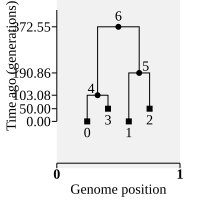

In [42]:
ts = msprime.sim_ancestry(
    samples = [
        msprime.SampleSet(1),  # Set sample size and time = present
        msprime.SampleSet(1, time=50)    # Ancient individual, time = 50 generations ago
    ],
    population_size = 100,   # The total population size from where we tool the sample
    random_seed = 42
)
SVG(ts.draw_svg(y_axis=True))

Note: sampled nodes are squares and the rest are circles.

The order of the details can be specified with SampleSet. end_time specifies until which generation the simulation will work, useful when we only focus in a timespan. In this case, we are interested only in the sampled individuals and their nodes.

In [43]:
demography = msprime.Demography.island_model([10, 10], migration_rate=1)
ts = msprime.sim_ancestry(
    samples = [
        msprime.SampleSet(1, population=1),   # Here we define the pop 1 before pop 0
        msprime.SampleSet(2, population=0)    ],
    demography = demography,
    end_time = 0    # Only focus on hyaplotypes from 0 generations ago. This basically stops simulations from doing anything
)
print(ts.tables.individuals)
print(ts.tables.nodes)

╔══╤═════╤════════╤═══════╤════════╗
║id│flags│location│parents│metadata║
╠══╪═════╪════════╪═══════╪════════╣
║0 │    0│        │       │        ║
║1 │    0│        │       │        ║
║2 │    0│        │       │        ║
╚══╧═════╧════════╧═══════╧════════╝

╔══╤════╤═════╤══════════╤══════════╤════════╗
║id│time│flags│population│individual│metadata║
╠══╪════╪═════╪══════════╪══════════╪════════╣
║0 │   0│    1│         1│         0│        ║
║1 │   0│    1│         1│         0│        ║
║2 │   0│    1│         0│         1│        ║
║3 │   0│    1│         0│         1│        ║
║4 │   0│    1│         0│         2│        ║
║5 │   0│    1│         0│         2│        ║
╚══╧════╧═════╧══════════╧══════════╧════════╝



## Poidy
It defines the number of nodes per sampled individual AND sets the time scale for continuous time coalescent models.
### Number of nodes
If defined in SampleSet. Example with one individual triploid and 2 haploid. In any case, simulations are ALWAYS run in haploid time scale.

In [44]:
# If defined in SampleSet. Example with one individual triploid and 2 haploid.
ts = msprime.sim_ancestry(samples = [
    msprime.SampleSet(1, ploidy=3), 
    msprime.SampleSet(2)],
    ploidy=1,  # Overwrites the default ploidy (2)
    end_time=0
)
print(ts.tables.individuals)
print(ts.tables.nodes)

╔══╤═════╤════════╤═══════╤════════╗
║id│flags│location│parents│metadata║
╠══╪═════╪════════╪═══════╪════════╣
║0 │    0│        │       │        ║
║1 │    0│        │       │        ║
║2 │    0│        │       │        ║
╚══╧═════╧════════╧═══════╧════════╝

╔══╤════╤═════╤══════════╤══════════╤════════╗
║id│time│flags│population│individual│metadata║
╠══╪════╪═════╪══════════╪══════════╪════════╣
║0 │   0│    1│         0│         0│        ║
║1 │   0│    1│         0│         0│        ║
║2 │   0│    1│         0│         0│        ║
║3 │   0│    1│         0│         1│        ║
║4 │   0│    1│         0│         2│        ║
╚══╧════╧═════╧══════════╧══════════╧════════╝



In [50]:
# If defined with an integer
ts = msprime.sim_ancestry(samples=2, ploidy=3, end_time=0)  # Like this, all the populations have the same features
print(ts.tables.individuals)
print(ts.tables.nodes)

╔══╤═════╤════════╤═══════╤════════╗
║id│flags│location│parents│metadata║
╠══╪═════╪════════╪═══════╪════════╣
║0 │    0│        │       │        ║
║1 │    0│        │       │        ║
╚══╧═════╧════════╧═══════╧════════╝

╔══╤════╤═════╤══════════╤══════════╤════════╗
║id│time│flags│population│individual│metadata║
╠══╪════╪═════╪══════════╪══════════╪════════╣
║0 │   0│    1│         0│         0│        ║
║1 │   0│    1│         0│         0│        ║
║2 │   0│    1│         0│         0│        ║
║3 │   0│    1│         0│         1│        ║
║4 │   0│    1│         0│         1│        ║
║5 │   0│    1│         0│         1│        ║
╚══╧════╧═════╧══════════╧══════════╧════════╝



### Coalescent time scale
Ploidy affects the time of coalescence because it determines how many nodes there are.

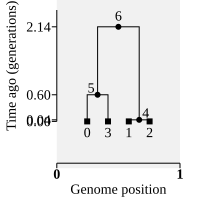

In [51]:
ts = msprime.sim_ancestry(
    samples=[msprime.SampleSet(4, ploidy=1)],
    population_size=1,
    ploidy=1,
    random_seed=1234
)
SVG(ts.draw_svg(y_axis=True))

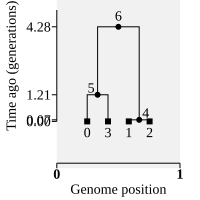

In [52]:
ts = msprime.sim_ancestry(
    samples=[msprime.SampleSet(4, ploidy=1)],
    population_size=1,
    ploidy=2,  # Node time increases by a factor of 2
    random_seed=1234
)
SVG(ts.draw_svg(y_axis=True))

## Genome Properties
### population size
Defining population size help to scale node times according to it.

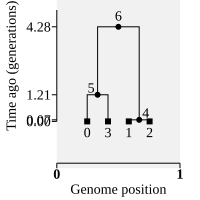

In [45]:
# First with the default for population_size parameter:
ts = msprime.sim_ancestry(2, random_seed=1234)
SVG(ts.draw_svg(y_axis=True))

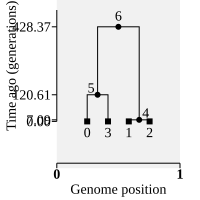

In [47]:
# Now with population size defined to 100
ts = msprime.sim_ancestry(2, population_size=100, random_seed=1234)
SVG(ts.draw_svg(y_axis=True))

### Sequence length
Defines the length of the chromosome to simulate. Default is 1 = 1 position in the genome only. This parameter makes little difference if no recombination or gene conversion is included because then it considerts only the ancestry of a non-recombining sequence (nada cambia en todo el segmento, igual a si considerara solo una posición). This is importantant if later we want to add mutations.

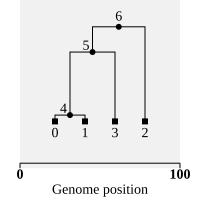

In [53]:
ts = msprime.sim_ancestry(2, sequence_length=100, random_seed=1)
SVG(ts.draw_svg())

### Demography
The model describes the set of populations to study, their migration rates and evolutionary events. 

If no demography is defined, default is a fixed size population of size 1.

Models like the Discrete Time Wright-Fisher DTWF need to get the population size explicitly, becuase it models populations of individuals, not time approximations. Because of this, populations with different size will have different results.

### Recombination
The recombination_rate in sim_ancestry allows to specify uniform and non-uniform rates in the genome.

Here makes sense to use recombination rate and sequence length. It produces several trees at different positions in the genome (or chromosome).

RateMap allows also for non-uniform recombination. RateMap also defines the sequence length to use. 

Recombination rate (as well as other rates) are given in units of sequence length per unit of time. An example for unit of sequence is an individual and for unit time could be generations, so rate would be per individuals per generation, but it could also be per haplotype and per coalescent units.

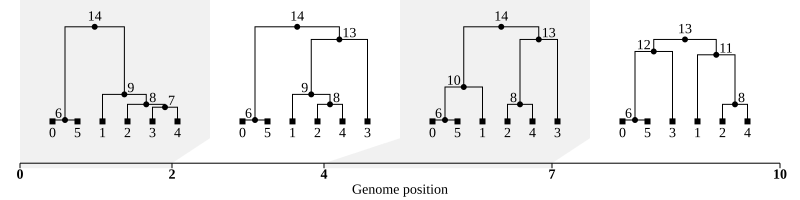

In [54]:
ts = msprime.sim_ancestry(samples=3,
                         recombination_rate=0.1,  # Per unit of sequence length, per unit of time (ex: per base pair, per generation)
                         sequence_length=10,
                         random_seed=2)
SVG(ts.draw_svg())

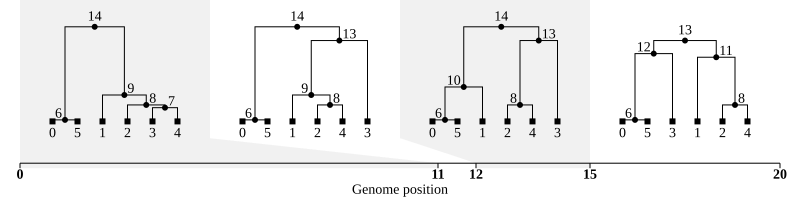

In [55]:
# non-uniform recombination, to simulate regions with different recombination rates
rate_map = msprime.RateMap(position=[0,10,20], rate=[0.01, 0.1])  # Here the first half has a rate of one tenth of the second half
ts = msprime.sim_ancestry(3, recombination_rate=rate_map, random_seed=2)
SVG(ts.draw_svg())

All the recombinations are in the segment from position 10 to 20. This makes sense because we defined that in this segment the recombination rate would be much higher (0.1) than the rate at other positions. It's defined as a high recombination region.

### Gene Conversion
Gene conversion is the copy of a portion of the genome to another genome. The mean length of the part copied is given by the parameter tract. If not given, the default is set randomly from a geometric distribution, so most of the event would fall proportionally near a mean length.

Before:
A:  A A A A [C C C] A A A
B:  A A A A [G G G] A A A

After:
A:  A A A A [C C C] A A A
B:  A A A A [C C C] A A A

In the example, the conversion event is at position 4.65-5.22 and there the tree is different, but the trees before and after are identical.


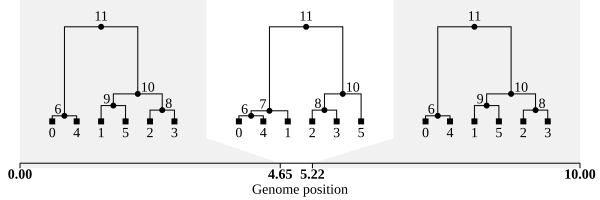

In [57]:
ts = msprime.sim_ancestry(
    3, gene_conversion_rate=0.02, gene_conversion_tract_length=1,
    sequence_length=10, random_seed=3, discrete_genome=False
)
SVG(ts.draw_svg())

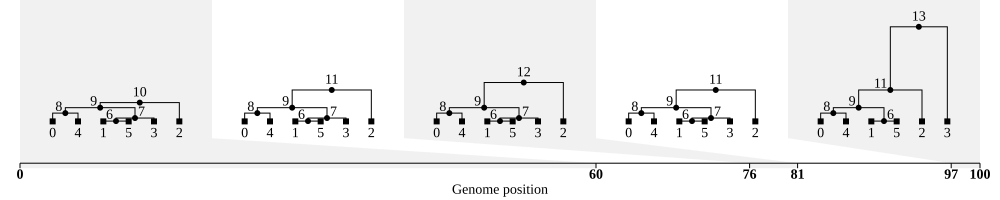

In [58]:
# Recomination + Gene Conversion
ts = msprime.sim_ancestry(3, sequence_length=100,
                         recombination_rate=0.003,
                         gene_conversion_rate=0.002,
                         gene_conversion_tract_length=5,
                         random_seed=6)
SVG(ts.draw_svg())

### Simulating multiple chromosomes
It is used to catch correlations between trees on different trees. Independent simulations are informative enough and require less time and resources but multiple simulations can be used for the following escenarios.
* under  fixed pedigree model. This is not very resource demanding because simulation can be done in parallel.
* DTWF: in large simulated cohorts where many samples can be related. Also for ancestry of very recently admixed populations.
* multiple menger coalescent: results in positive correlated ancestries between unlinked chromosomes.
 
These simulations should always be under a discrete genome.

In [62]:
# Example Pedigree
import io
import tskit
ped_txt = """\
# id parent0 parent1 time is_sample
0   2   3   0.0 1
1   4   5   0.0 1
2   6   7   1.0 0
3   8   9   1.0 0
4   6   7   1.0 0
5   10  11  1.0 0
6   .   .   2.0 0
7   .   .   2.0 0
8   .   .   2.0 0
9   .   .   2.0 0
10  .   .   2.0 0
11  .   .   2.0 0
"""
pedigree = msprime.parse_pedigree(io.StringIO(ped_txt), sequence_length=100)
ts = pedigree.tree_sequence()

print(ts)
print(ts.draw_text())

╔═══════════════════════════╗
║TreeSequence               ║
╠═══════════════╤═══════════╣
║Trees          │          1║
╟───────────────┼───────────╢
║Sequence Length│        100║
╟───────────────┼───────────╢
║Time Units     │generations║
╟───────────────┼───────────╢
║Sample Nodes   │          4║
╟───────────────┼───────────╢
║Total Size     │    1.6 KiB║
╚═══════════════╧═══════════╝
╔═══════════╤════╤═════════╤════════════╗
║Table      │Rows│Size     │Has Metadata║
╠═══════════╪════╪═════════╪════════════╣
║Edges      │   0│  8 Bytes│          No║
╟───────────┼────┼─────────┼────────────╢
║Individuals│  12│654 Bytes│         Yes║
╟───────────┼────┼─────────┼────────────╢
║Migrations │   0│  8 Bytes│          No║
╟───────────┼────┼─────────┼────────────╢
║Mutations  │   0│ 16 Bytes│          No║
╟───────────┼────┼─────────┼────────────╢
║Nodes      │  24│680 Bytes│          No║
╟───────────┼────┼─────────┼────────────╢
║Populations│   1│224 Bytes│         Yes║
╟───────────┼────┼────

### Storage options
msprime optimases storage by not saving events, but their effects in outcome, and not saving events that do not lead to coalescence. This can be modified with additional_nodes passing a nodeType. 

To specify the node types we want to store information, we use NodeType which are ordered by a numeric constant which flag the types at the node table. To compare several node typer we use bitwise operations (| &...). This same operation is also used to give different colours to nodes.

It is also possible to store the whole length of the ancestral material involved in the coalescence, not just the overlapping segments of the genome.

## Events
### Common ancestors
Difference between coalescence event and common ancestor event: both events mean that the segments of genomes (or lineages) analysed come from the same ancestor, but in the coaescence the lineages merge in the past, while in common ancestor they do not merge because the lineages analysed are in two different segments so they are not inheritate together. They never coalesce because they come separate in another segment even though they come from the same ancestor.
### Recombination events
This produces a node to have 2 ancestors (opposite to coalesscence), one ancestor node for the left side of the braking point marking the recombination and the other node for the right part. Usefull to identify segments of the genome that passes from one parent or the other.
### Migration events
The precise sequence of migration events can be stored with record_migration=True y additional_nodes=msprime.NodeType.MIGRANT

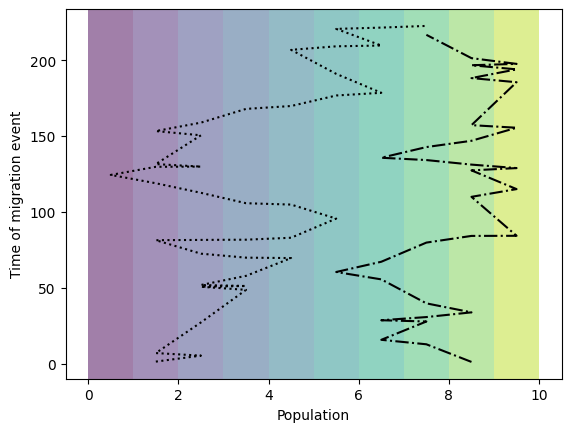

In [75]:
# Trace migration history of 2 samples back in time to their common ancestor
# 10 populations
N=10
demography = msprime.Demography.stepping_stone_model(
    [20] * N, migration_rate=0.1, boundaries=True
)
ts = msprime.sim_ancestry(
    {0:1, N-1: 1}, #one sample from populations 0 and 9
    demography = demography,
    record_migrations=True,
    additional_nodes=msprime.NodeType.MIGRANT,
    coalescing_segments_only=False,
    random_seed=6
)

# Visualization: Each population in the model has different colour and position on x axis
# and time in y-axis

import tskit
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

cmap = plt.colormaps['viridis']
tree = ts.first()
mig_color_dict = {}

for u, linestyle in zip(ts.samples()[::2], ["dotted", "dashdot"]):
    mig = ts.tables.migrations
    loc = []
    time = []

    while u != tskit.NULL:
        migs = np.where(mig.node == u)[0]
        for cur_mig in migs:
            cur_mig = mig[cur_mig]
            loc.append(cur_mig.dest+ 0.5)
            time.append(cur_mig.time)
        u = tree.parent(u)
    plt.plot(loc, time, linestyle=linestyle, color="black")
for i in range(N):
    rgba = cmap(i/N)
    mig_color_dict[i] = np.array(rgba)*255
    plt.axvspan(i,i+1, facecolor=rgba, alpha=0.5)

plt.ylabel("Time of migration event")
plt.xlabel("Population")
plt.show()

### Ancestral Recobination Graphs (ARGs)


## Demographic Models
To change the default model of a fixed-size, single randomly mating population, we can add demographic events.

A demography object encapsulates a model.

### Trunk Model


In [3]:
import msprime
import numpy as np
import math

# Time in generations
generation_time = 25
T_OOA = 21.2e3 / generation_time
T_AMH = 140e3 / generation_time
T_ANC = 220e3 /generation_time

r_CEU = 0.004
r_CHB = 0.0055    # Important to add after bottleneck
N_CEU = 1000 / math.exp(-r_CEU * T_OOA)  
N_CHB = 510 / math.exp(-r_CHB * T_OOA)

demography = msprime.Demography()

demography.add_population(  #The trunk population
    name="YRI",
    description="Africa",
    initial_size=123000,
    initially_active=True,
);
demography.add_population(
    name="CEU",
    description="European",
    initial_size=N_CEU,
    growth_rate=r_CEU,
)
demography.add_population(
    name="CHB",
    description="East Asian",
    initial_size=N_CHB,
    growth_rate=r_CHB,
)
demography.add_population(
    name="OOA",
    description="Bottleneck out-of-Africa population",
    initial_size=2100,
)

# Set migration rates between extant populations
demography.set_symmetric_migration_rate(["CEU", "CHB"], 9.6e-5)
demography.set_symmetric_migration_rate(["YRI", "CHB"], rate=25e-5)
demography.set_symmetric_migration_rate(["YRI", "CEU"], 3e-5)

# Set coalescence events
demography.add_population_split(
    time=T_OOA, derived=["CEU", "CHB"], ancestral="OOA" # Split between Eur and East Asian
)
demography.add_symmetric_migration_rate_change(
    time=T_OOA, populations=["YRI", "OOA"], rate=25e-5
)
demography.add_population_split(
    time=T_AMH, derived=["OOA"], ancestral="YRI"
)
demography.add_population_parameters_change(
    time=T_ANC, population="YRI", initial_size=7300
);


### Example with American model

In [7]:
import msprime
import numpy as np
import math

# ------------------------------------------------------------
# 1. Demographic parameters
# ------------------------------------------------------------

generation_time = 25

# Times in generations
T_EAS = 20_000 / generation_time       # Africa -> East Asia
T_AMR = 15_000 / generation_time       # East Asia -> America
T_ANC = 200_000 / generation_time      # Ancestral population

# Population sizes
N_AFR = 15_000
N_EAS = 2_000
N_AMR = 1_000
N_ANC = 7_000

# ------------------------------------------------------------
# 2. Build demographic model
# ------------------------------------------------------------

demography = msprime.Demography()

# Present-day populations
demography.add_population(
    name="AFR",
    description="African population",
    initial_size=N_AFR,
)

demography.add_population(
    name="EAS",
    description="East Asian population",
    initial_size=N_EAS,
)

demography.add_population(
    name="AMR",
    description="American population",
    initial_size=N_AMR,
)


# ------------------------------------------------------------
# 3. Population history
# ------------------------------------------------------------

# America splits from East Asia
demography.add_population_split(
    time=T_AMR,
    derived=["AMR"],
    ancestral="EAS",
)

# East Asia splits from Africa
demography.add_population_split(
    time=T_EAS,
    derived=["EAS"],
    ancestral="AFR",
)

# Ancient population size change
demography.add_population_parameters_change(
    time=T_ANC,
    population="AFR",
    initial_size=N_ANC,
)

# ------------------------------------------------------------
# 4. Simulate genomes
# ------------------------------------------------------------

samples = {
    "AFR": 50,
    "EAS": 50,
    "AMR": 50,
}

ts = msprime.sim_ancestry(
    samples=samples,
    demography=demography,
    sequence_length=1e6,
    recombination_rate=1e-8,
    random_seed=1234,
)

# Add mutations
mts = msprime.sim_mutations(
    ts,
    rate=1.2e-8,
    random_seed=5678,
)

# ------------------------------------------------------------
# 5. Calculate Tajima's D
# ------------------------------------------------------------


for population in ["AFR", "EAS", "AMR"]:
    pop_id = [p.id for p in demography.populations if p.name == population][0]
    sample_nodes = mts.samples(population=pop_id)

    # Diversity statistics for this population

    diversity = mts.diversity(
        sample_sets=sample_nodes,
    )


    tajimas_d = mts.Tajimas_D(
        sample_sets=sample_nodes,
    )

    print(f"{population}:")
    print(f"  nucleotide diversity (pi) = {diversity:.6f}")
    print(f"  Tajima's D = {tajimas_d:.3f}")

AFR:
  nucleotide diversity (pi) = 0.000419
  Tajima's D = -0.721
EAS:
  nucleotide diversity (pi) = 0.000402
  Tajima's D = 0.127
AMR:
  nucleotide diversity (pi) = 0.000300
  Tajima's D = 1.576
